In [108]:
import simsopt.configs.zoo as zoo
import numpy as np
import matplotlib.pyplot as plt
from simsopt.geo import CurveXYZFourier
from simsopt.field import Current, Coil, BiotSavart, coils_via_symmetries
coils, currents, ma = zoo.get_w7x_data()

/var/folders/jc/b9r1lwld74jfg3kzdjjk6_gc0000gn/T/ipykernel_62825/80311645.py:6: DeprecationWarning: get_w7x_data is deprecated and will be removed in the next major release; please use get_data('w7x', coil_order=..., magnetic_axis_order=..., points_per_period=...) instead.
  coils, currents, ma = zoo.get_w7x_data()


In [ ]:
field = BiotSavart(coils_via_symmetries(coils, currents, nfp = 5, stellsym = True))
field.set_points(np.array([[0.5, 0.5, 0.1], [0.1, 0.1, -0.3]]))
print(field.B())

[[-4.45842904e-05  3.18847545e-05 -3.33056649e-03]
 [ 2.49651437e-05  2.50914179e-05 -3.05308091e-03]]


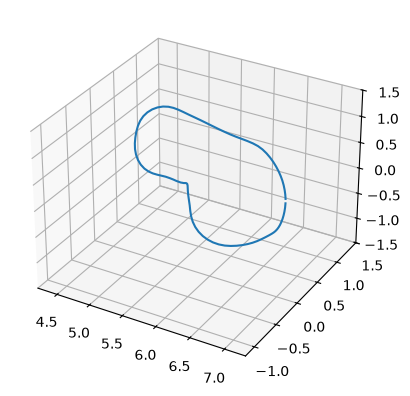

In [124]:
curve = coils[0]
xyz = curve.gamma() # want to perturb each xyz coordiante with GP 
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
plt.plot(xyz[:,0], xyz[:,1],xyz[:,2])
ax.set(xlim=(4.2,7.3),
       ylim= (-1.2,1.5),
       zlim= (-1.5,1.5))
plt.show()

In [150]:
curve.quadpoints

array([0.        , 0.01041667, 0.02083333, 0.03125   , 0.04166667,
       0.05208333, 0.0625    , 0.07291667, 0.08333333, 0.09375   ,
       0.10416667, 0.11458333, 0.125     , 0.13541667, 0.14583333,
       0.15625   , 0.16666667, 0.17708333, 0.1875    , 0.19791667,
       0.20833333, 0.21875   , 0.22916667, 0.23958333, 0.25      ,
       0.26041667, 0.27083333, 0.28125   , 0.29166667, 0.30208333,
       0.3125    , 0.32291667, 0.33333333, 0.34375   , 0.35416667,
       0.36458333, 0.375     , 0.38541667, 0.39583333, 0.40625   ,
       0.41666667, 0.42708333, 0.4375    , 0.44791667, 0.45833333,
       0.46875   , 0.47916667, 0.48958333, 0.5       , 0.51041667,
       0.52083333, 0.53125   , 0.54166667, 0.55208333, 0.5625    ,
       0.57291667, 0.58333333, 0.59375   , 0.60416667, 0.61458333,
       0.625     , 0.63541667, 0.64583333, 0.65625   , 0.66666667,
       0.67708333, 0.6875    , 0.69791667, 0.70833333, 0.71875   ,
       0.72916667, 0.73958333, 0.75      , 0.76041667, 0.77083

In [149]:
2*np.pi*np.multiply.outer(np.asarray(curve.quadpoints, float), np.arange(1, 49))

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [6.54498469e-02, 1.30899694e-01, 1.96349541e-01, ...,
        3.01069296e+00, 3.07614281e+00, 3.14159265e+00],
       [1.30899694e-01, 2.61799388e-01, 3.92699082e-01, ...,
        6.02138592e+00, 6.15228561e+00, 6.28318531e+00],
       ...,
       [6.08683577e+00, 1.21736715e+01, 1.82605073e+01, ...,
        2.79994445e+02, 2.86081281e+02, 2.92168117e+02],
       [6.15228561e+00, 1.23045712e+01, 1.84568568e+01, ...,
        2.83005138e+02, 2.89157424e+02, 2.95309709e+02],
       [6.21773546e+00, 1.24354709e+01, 1.86532064e+01, ...,
        2.86015831e+02, 2.92233567e+02, 2.98451302e+02]], shape=(96, 48))

In [170]:
def gp_perturbation_analytic(curve, sigma, length_scale, n_terms=None, rng=None):
    """
    Zero-mean GP perturbation of 3D points parametrized by t.

    t            : (N,) parameter values (for simsopt curves, curve.quadpoints in [0, 1))
    sigma        : standard deviation of the perturbation (meters)
    length_scale : SE length scale, in the same units as t
    n_terms      : number of KL modes kept (None = all N)
    periodic     : wrap the kernel with period 1 so closed curves stay closed
    Returns delta of shape (N, 3); x, y, z are independent GPs with the same kernel.
    """
    rng = np.random.default_rng(rng)
    t = np.asarray(curve.quadpoints, dtype=float)
    N = len(t) # number of points
    n_terms = n_terms if n_terms is not None else curve.order
    d = t[:, None] - t[None, :]
    k = np.arange(1,n_terms+1) # (n,)

    S_n = sigma**2 * length_scale * 1/np.sqrt(2 * np.pi) * np.exp(-0.5 * (length_scale *k)**2) # (n,)
    # double check spectral density for periodic SE kernel
    c0 = sigma**2 * length_scale * 1/np.sqrt(2 * np.pi) * rng.standard_normal(3) # (3,)
    a = np.sqrt(2*S_n)[:, None] * rng.standard_normal((n_terms, 3))  # (n,3) independent weights per coordinate
    b = np.sqrt(2*S_n)[:, None] * rng.standard_normal((n_terms, 3))  # (n,3) independent weights per coordinate

    def delta(t):
        ang = 2*np.pi*np.multiply.outer(np.asarray(t, float), k) # (N,n)
        return c0 + np.cos(ang) @ a + np.sin(ang) @ b # (N,3)

    return delta(t), (c0, a, b), S_n

In [ ]:
def gp_perturbation(t, sigma, length_scale, n_terms=None, periodic=True, rng=None):
    """
    Zero-mean GP perturbation of 3D points parametrized by t.

    t            : (N,) parameter values (for simsopt curves, curve.quadpoints in [0, 1))
    sigma        : standard deviation of the perturbation (meters)
    length_scale : SE length scale, in the same units as t
    n_terms      : number of KL modes kept (None = all N)
    periodic     : wrap the kernel with period 1 so closed curves stay closed
    Returns delta of shape (N, 3); x, y, z are independent GPs with the same kernel.
    """
    rng = np.random.default_rng(rng)
    t = np.asarray(t, dtype=float)
    N = len(t)
    d = t[:, None] - t[None, :]

    if periodic:
        # Sum of SE kernels over periodic images: still positive semi-definite
        K = sum(np.exp(-0.5 * ((d + m) / length_scale) ** 2) for m in range(-3, 4))
    else:
        K = np.exp(-0.5 * (d / length_scale) ** 2)
    K = sigma**2 * K

    w, V = np.linalg.eigh(K)
    idx = np.argsort(w)[::-1]
    w, V = np.clip(w[idx], 0, None), V[:, idx]

    n = N if n_terms is None else min(n_terms, N)
    z = rng.standard_normal((n, 3))                 # independent weights per coordinate
    return V[:, :n] @ (np.sqrt(w[:n])[:, None] * z)  # (N, 3), zero mean

In [ ]:
def k(x, sigma = 0.01, l = 0.4*np.pi):
    k = sigma**2 * np.exp(-0.5 * (x/l)**2)
    return k

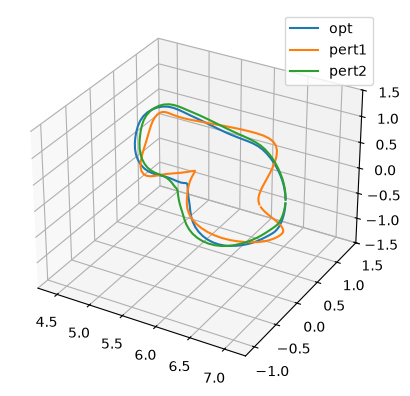

In [181]:
del_xyz = gp_perturbation(curve.quadpoints, sigma=0.3, length_scale=0.01, n_terms=10, periodic=True)
xyz_pert = xyz + del_xyz

del2_xyz,_, Sn = gp_perturbation_analytic(curve, sigma=0.3, length_scale=0.01, n_terms=3)
xyz_pert2 = xyz + del2_xyz

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
plt.plot(xyz[:,0], xyz[:,1],xyz[:,2], label = 'opt')
plt.plot(xyz_pert[:,0], xyz_pert[:,1],xyz_pert[:,2], label = 'pert1')
plt.plot(xyz_pert2[:,0], xyz_pert2[:,1],xyz_pert2[:,2], label = 'pert2')
ax.set(xlim=(4.2,7.3),
       ylim= (-1.2,1.5),
       zlim= (-1.5,1.5))
plt.legend()
plt.show()

In [144]:
current= currents[0].current

In [146]:
c = CurveXYZFourier(curve.quadpoints, order = curve.order)
c.least_squares_fit(xyz_pert)
coil_pert = Coil(c, Current(current))

field_new = BiotSavart([coil_pert])
field_new.set_points(np.array([[0.5, 0.5, 0.1], [0.1, 0.1, -0.3]]))
print(field_new.B())


[[0.00170994 0.00408977 0.00090223]
 [0.0004643  0.00335766 0.00078674]]


In [147]:
field = BiotSavart(coils_via_symmetries(coils, currents, nfp = 2, stellsym = True))
field.set_points(np.array([[0.5, 0.5, 0.1], [0.1, 0.1, -0.3]]))
print(field.B())

[[ 0.01895896  0.01855101 -0.00150231]
 [ 0.00371339  0.00363996 -0.00120056]]
